# FL-ATTACK-003.4 — Gradient leakage (DLG/iDLG, analytic inversion)

*Epic EPIC-001 · story fl_attack_003 · all results below are loaded from files produced by the task's experiment function and labelled MEASURED/SIMULATED; clients are virtual; data is synthetic.*

## 1. Research objective
Reconstruct inputs from shared gradients and test mitigation via aggregation and noise.

## 2. Scientific background
Gradients leak inputs [zhu2019, zhao2020, geiping2020]; for batch size 1 and a first dense layer, inversion is analytic.

References use keys of `docs/references/references_master.md` (status per entry).

## 3. Research questions
- **RQ1.** When does reconstruction succeed (batch size, hidden width, noise)?
- **RQ2.** Does aggregation over clients protect?

## 4. Hypotheses
- **H1.** Success is high for B=1,2 plaintext and falls with batch size/aggregation/noise.

## 5. Mathematical formulation
min_x ||∇_W L(f(x),y) − g||²; analytic: x = (∂L/∂W₁ row)/(∂L/∂b₁ entry). Success = relative L2 error ≤ 0.1 after Hungarian matching.

## 6. Experimental environment

In [1]:
import os, sys, json, platform, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
def _find_root():
    p = Path(os.environ.get("FL_ROOT") or os.environ.get("RS_ROOT") or Path.cwd()).resolve()
    for q in [p, *p.parents]:
        if (q / "src" / "federated_learning").exists():
            return q
    raise RuntimeError("repository root not found; set RS_ROOT")
ROOT = _find_root()
sys.path.insert(0, str(ROOT / "src"))
STORY = "fl_attack_003"
_cands = [ROOT / "experiments" / "results" / STORY]
RES = next(c for c in _cands if c.exists())
import numpy as np, pandas as pd
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
SEED = 0; np.random.seed(SEED)
def show_csv(name, n=12):
    p = RES / name
    if p.exists(): display(pd.read_csv(p).round(4).head(n))
    else: print("MISSING", name)
def show_fig(name):
    for base in (RES / "figures", RES):
        if (base / name).exists(): display(Image(filename=str(base / name))); return
    print("MISSING figure", name)
print("root:", ROOT, "| results:", RES)

root: /home/claude/fl_sprint | results: /home/claude/fl_sprint/experiments/results/fl_attack_003


In [2]:
import importlib.metadata as md
vers = {}
for p in ["numpy","scipy","scikit-learn","torch","tenseal","phe","pandas","matplotlib","cryptography","psutil","mlflow","opacus"]:
    try: vers[p] = md.version(p)
    except Exception: vers[p] = "not installed"
print(json.dumps(dict(python=platform.python_version(), platform=platform.platform(), versions=vers, seed=SEED, gpu="none (CPU only; GPU metrics NOT_MEASURED)"), indent=1))

{
 "python": "3.13.18",
 "platform": "Linux-6.18.44-fc-v338-x86_64-with-glibc2.39",
 "versions": {
  "numpy": "2.5.3",
  "scipy": "1.18.1",
  "scikit-learn": "1.9.1",
  "torch": "2.15.0",
  "tenseal": "0.3.18",
  "phe": "1.5.0",
  "pandas": "3.0.5",
  "matplotlib": "3.11.2",
  "cryptography": "50.0.1",
  "psutil": "7.2.2",
  "mlflow": "3.18.0",
  "opacus": "1.6.0"
 },
 "seed": 0,
 "gpu": "none (CPU only; GPU metrics NOT_MEASURED)"
}


## 7. Dataset description
Synthetic binary tabular dataset **SYN-IDS-v1** (scikit-learn `make_classification`, 40 features, 70:30 split). Chosen because no real IDS/clinical dataset was available in the sandbox. It has no clinical meaning; conclusions about absolute accuracy do not transfer.

In [3]:
from federated_learning.synthetic_data.generators.syn_ids_v1 import make_dataset, DATASET_ID
from federated_learning.data_partitioning.iid import partition_iid
from federated_learning.data_partitioning.dirichlet import partition_dirichlet
from federated_learning.data_partitioning.metrics import label_skew_stat
data = make_dataset(n_samples=6000, seed=SEED)
print(DATASET_ID, "train", data.X_train.shape, "test", data.X_test.shape, "positive rate", float(data.y_train.mean()))
print("NOTE: SYNTHETIC tabular data (not CIC-IDS-2017, not patient data); clients are VIRTUAL, not hospitals.")

SYN-IDS-v1 train (4200, 40) test (1800, 40) positive rate 0.40095238095238095
NOTE: SYNTHETIC tabular data (not CIC-IDS-2017, not patient data); clients are VIRTUAL, not hospitals.


## 8. Configuration and reproducibility settings
Seeds are fixed; each stored result carries `provenance` (experiment id, SHA-256 of the configuration, environment versions; `git_commit` is `null` because the workspace is not a git repository).

In [4]:
from federated_learning.training.config import FLConfig
cfg = FLConfig(rounds=5, local_epochs=1, seed=SEED)
print(cfg)

FLConfig(algo='fedavg', rounds=5, local_epochs=1, lr=0.05, batch_size=32, participation=1.0, mu=0.0, hidden=32, act='relu', seed=0, hetero_epochs=False, eval_every=1, server_lr=1.0)


## 9. Data preparation
Partitioning into virtual clients (IID or Dirichlet label skew) is performed by `federated_learning.data_partitioning`.

In [5]:
parts_iid = partition_iid(data.y_train, 10, SEED)
parts_dir = partition_dirichlet(data.y_train, 10, 0.3, SEED)
print('label-skew statistic IID:', round(label_skew_stat(data.y_train, parts_iid),3), ' Dirichlet(0.3):', round(label_skew_stat(data.y_train, parts_dir),3))

label-skew statistic IID: 0.019  Dirichlet(0.3): 0.363


## 10. Implementation
Reusable code lives in `src/federated_learning/` (`attacks.py`, `defenses.py`, `fl.py`). The cell below exercises it live (small, fast, deterministic) and asserts correctness.

In [6]:
from federated_learning import attacks as A
from federated_learning.training.models import build_model, get_flat
m = build_model(40, 32, "sigmoid"); w = get_flat(m); X, y = data.X_test[:2], data.y_test[:2]
g = A.model_grad(m, w, X, y); Xh = A.dlg_attack(m, w, g, 2, 40, labels=y, iters=300, seed=SEED)
print("DLG on B=2 plaintext gradient:", A.match_and_score(X, Xh))
m1 = build_model(40, 16, "sigmoid"); w1 = get_flat(m1); g1 = A.model_grad(m1, w1, data.X_test[:1], data.y_test[:1])
xa = A.analytic_first_layer_inversion(g1, 40, 16); print("analytic B=1 relative error:", float(np.linalg.norm(xa - data.X_test[0]) / np.linalg.norm(data.X_test[0])))

DLG on B=2 plaintext gradient: {'success_rate': 1.0, 'mean_rel_err': 0.00017959644901566207, 'mse': 2.5410662018998664e-08, 'feat_acc': 1.0}
analytic B=1 relative error: 5.111634671095544e-09


## 11. Experiment execution
The full experiment was executed by `python -m federated_learning.pipelines.experiments.run_all --task FL-ATTACK-003.4` (see `logs/`). Its raw per-run results are loaded here; they are not re-computed inside the notebook.

In [7]:
show_csv('task_3_4_runs.csv')
show_csv('task_3_4_analytic.csv')

,factor,hidden,n_params,batch,aggregated_clients,dp_noise_rel,success_rate,mean_rel_err,mse,feat_acc,model_acc,seconds
0,batch/architecture,8,346,1,1,0.0,1.0000,0.0000,0.0000,1.0000,0.6578,0.8683
1,batch/architecture,8,346,2,1,0.0,1.0000,0.0002,0.0000,1.0000,0.6578,4.4374
2,batch/architecture,8,346,4,1,0.0,0.2250,0.7727,1.1062,0.3150,0.6578,7.7366
3,batch/architecture,8,346,8,1,0.0,0.0000,1.1249,1.1426,0.0828,0.6578,7.9688
4,batch/architecture,8,346,16,1,0.0,0.0000,1.1804,1.3259,0.0692,0.6578,7.3037
5,batch/architecture,32,1378,1,1,0.0,1.0000,0.0000,0.0000,1.0000,0.6183,0.3184
6,batch/architecture,32,1378,2,1,0.0,0.8000,0.1034,0.0508,0.8387,0.6183,6.9578
7,batch/architecture,32,1378,4,1,0.0,0.3500,0.4885,0.5285,0.4931,0.6183,8.0906
8,batch/architecture,32,1378,8,1,0.0,0.0625,0.6663,0.5066,0.2294,0.6183,7.8377
9,batch/architecture,32,1378,16,1,0.0,0.0000,1.0218,1.0108,0.0939,0.6183,8.0235


,noise_rel,success_rate,median_rel_err
0,0.00,1.0,0.0000
1,0.01,1.0,0.0164
2,0.10,0.1,0.1706
3,0.50,0.0,0.8054
4,1.00,0.0,1.0229


## 12. Metrics collection
Metric definitions: MEASURED over seeds: attack metric (ASR / AUC / success rate), clean accuracy, defense cost. Intensity levels low/medium/high are defined in docs/fl_attack_003/attack_methodology.md.

In [8]:
show_csv('task_3_4_runs.csv')

,factor,hidden,n_params,batch,aggregated_clients,dp_noise_rel,success_rate,mean_rel_err,mse,feat_acc,model_acc,seconds
0,batch/architecture,8,346,1,1,0.0,1.0000,0.0000,0.0000,1.0000,0.6578,0.8683
1,batch/architecture,8,346,2,1,0.0,1.0000,0.0002,0.0000,1.0000,0.6578,4.4374
2,batch/architecture,8,346,4,1,0.0,0.2250,0.7727,1.1062,0.3150,0.6578,7.7366
3,batch/architecture,8,346,8,1,0.0,0.0000,1.1249,1.1426,0.0828,0.6578,7.9688
4,batch/architecture,8,346,16,1,0.0,0.0000,1.1804,1.3259,0.0692,0.6578,7.3037
5,batch/architecture,32,1378,1,1,0.0,1.0000,0.0000,0.0000,1.0000,0.6183,0.3184
6,batch/architecture,32,1378,2,1,0.0,0.8000,0.1034,0.0508,0.8387,0.6183,6.9578
7,batch/architecture,32,1378,4,1,0.0,0.3500,0.4885,0.5285,0.4931,0.6183,8.0906
8,batch/architecture,32,1378,8,1,0.0,0.0625,0.6663,0.5066,0.2294,0.6183,7.8377
9,batch/architecture,32,1378,16,1,0.0,0.0000,1.0218,1.0108,0.0939,0.6183,8.0235


## 13. Statistical analysis
95% CIs over seeds; AUC/ASR CIs may extend beyond [0,1] because they are t-intervals on few seeds (reported as computed).

In [9]:
show_csv('task_3_4_runs.csv', 30)

,factor,hidden,n_params,batch,aggregated_clients,dp_noise_rel,success_rate,mean_rel_err,mse,feat_acc,model_acc,seconds
0,batch/architecture,8,346,1,1,0.00,1.0000,0.0000,0.0000,1.0000,0.6578,0.8683
1,batch/architecture,8,346,2,1,0.00,1.0000,0.0002,0.0000,1.0000,0.6578,4.4374
2,batch/architecture,8,346,4,1,0.00,0.2250,0.7727,1.1062,0.3150,0.6578,7.7366
3,batch/architecture,8,346,8,1,0.00,0.0000,1.1249,1.1426,0.0828,0.6578,7.9688
4,batch/architecture,8,346,16,1,0.00,0.0000,1.1804,1.3259,0.0692,0.6578,7.3037
5,batch/architecture,32,1378,1,1,0.00,1.0000,0.0000,0.0000,1.0000,0.6183,0.3184
6,batch/architecture,32,1378,2,1,0.00,0.8000,0.1034,0.0508,0.8387,0.6183,6.9578
7,batch/architecture,32,1378,4,1,0.00,0.3500,0.4885,0.5285,0.4931,0.6183,8.0906
8,batch/architecture,32,1378,8,1,0.00,0.0625,0.6663,0.5066,0.2294,0.6183,7.8377
9,batch/architecture,32,1378,16,1,0.00,0.0000,1.0218,1.0108,0.0939,0.6183,8.0235


## 14. Visualizations

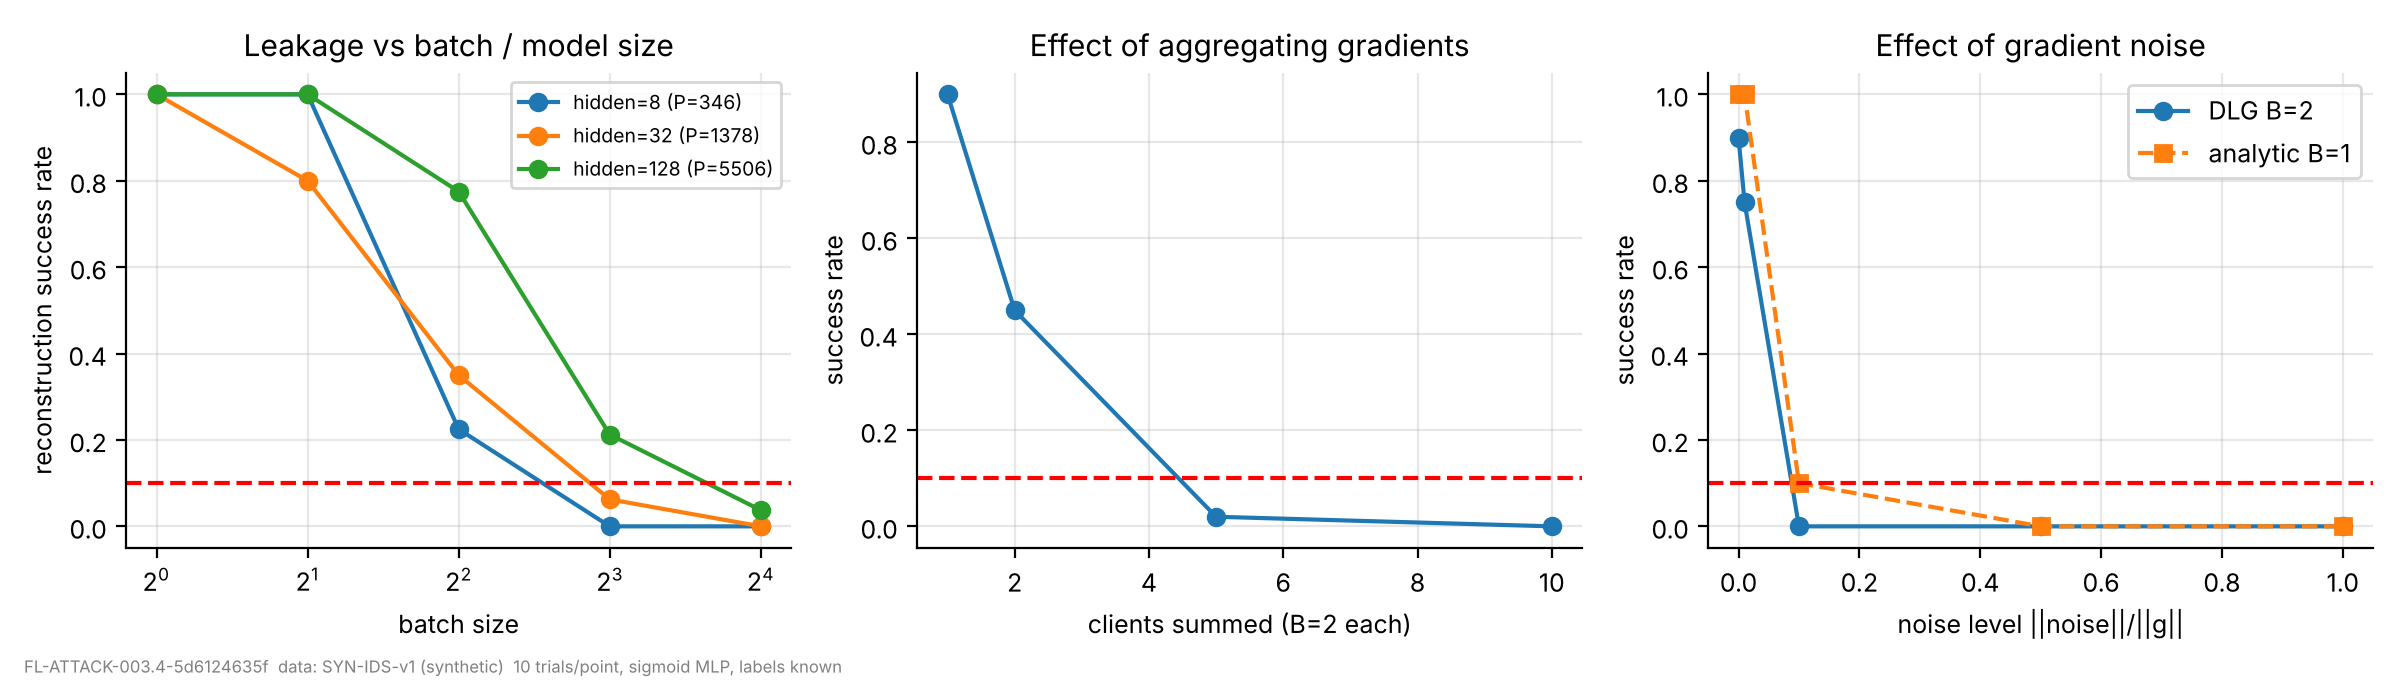

In [10]:
show_fig('task_3_4_gradient_leakage.png')

## 15. Interpretation of results
The numbers are computed in the next cell from the stored data; the text interprets only what that cell prints.

Plaintext small-batch updates are reconstructed; aggregated/noised updates are not (printed).

In [11]:
J = json.load(open(RES / 'task_3_4_gradient_leakage.json')); print([k for k in J if k != 'provenance'])

['rows', 'analytic', 'notes']


## 16. Limitations
- Sigmoid MLP, small models; deep CNN attacks not evaluated.
- Synthetic data, virtual clients on one machine, 2 CPU cores, no GPU; no real network. Comm. bytes are logical payload sizes.
- No regulatory/compliance conclusion can be drawn from this notebook.

## 17. Conclusions
Gradient-leakage KPI is NOT met for plaintext small-batch updates.

**Jira acceptance:** see `docs/fl_attack_003/results_and_discussion.md` for the criterion-by-criterion verdict (MET / PARTIALLY MET / NOT MET).

## 18. References
`zhu2019`, `zhao2020`, `geiping2020` — details in `docs/fl_attack_003/references.md`.